# CodeNova AI/ML Batch 01 — Task 1: Exploratory Data Analysis (EDA)
**Dataset:** Titanic passenger dataset (public sample dataset)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Purpose:** Profile and clean a real dataset, visualize distributions and relationships, detect potential outliers, and document evidence-based findings.

> Run every cell from top to bottom in Google Colab. The notebook downloads a public CSV, so an internet connection is needed for the first data-loading step. This is a learning dataset; findings describe this dataset and should not be treated as causal conclusions about all passengers or other populations.

## 1. Setup
The required libraries are commonly available in Google Colab. If a package import fails, uncomment and run the installation line below.

In [1]:
# If needed, uncomment:
# %pip install pandas numpy matplotlib seaborn

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

OUTPUT_DIR = "eda_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["savefig.dpi"] = 300

print("Setup complete. Output folder:", OUTPUT_DIR)

Setup complete. Output folder: eda_outputs


## 2. Load the public dataset
We use the public Titanic CSV maintained in the `datasciencedojo/datasets` GitHub repository. It is small enough for a beginner and includes numeric and categorical columns, missing values, and variables suitable for a range of plots.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df_original = pd.read_csv(DATA_URL)
df = df_original.copy()

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Dataset loaded successfully.
Rows: 891 | Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Dataset profiling
Inspect shape, column names, data types, non-null counts, summary statistics, and number of unique values. These checks help identify columns that need cleaning and determine which visualizations are appropriate.

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumeric summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include=["object"]).T)

profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(profile.sort_values("missing_percent", ascending=False))

Shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292



Categorical summary:


C:\Users\chand\AppData\Local\Temp\ipykernel_10804\307027483.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=["object"]).T)


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


,dtype,non_null,missing_count,missing_percent,unique_values
Cabin,str,204,687,77.10,147
Age,float64,714,177,19.87,88
Embarked,str,889,2,0.22,3
PassengerId,int64,891,0,0.00,891
Name,str,891,0,0.00,891
Pclass,int64,891,0,0.00,3
Survived,int64,891,0,0.00,2
Sex,str,891,0,0.00,2
Parch,int64,891,0,0.00,7
SibSp,int64,891,0,0.00,7


## 4. Missing values and duplicates
### Cleaning decisions (with rationale)
- **Age:** impute missing ages using the median within passenger class and sex, then fall back to the overall median if a group median is unavailable. Median is less affected by extreme values than the mean, and the groups provide a more relevant reference than one global value.
- **Embarked:** fill missing values with the most frequent port because it is a small categorical gap. This is a simple baseline choice, not proof of the missing passenger's port.
- **Cabin:** the cabin/deck field is missing for a large share of rows in this dataset. Rather than invent cabin values, we will exclude this field from the cleaned analysis copy and document the limitation.
- **Other columns:** leave missing values in place unless needed for a particular analysis; do not silently invent data.
- **Duplicates:** remove only exact duplicate rows across all columns. Repeated passenger attributes alone are not enough to conclude that two records are duplicates.

In [4]:
missing_before = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({
    "missing_count": missing_before,
    "missing_percent": (missing_before / len(df) * 100).round(2)
}))

exact_duplicates = int(df.duplicated().sum())
print("Exact duplicate rows before cleaning:", exact_duplicates)

df_clean = df.drop_duplicates().copy()

# Impute Age by passenger class and sex, then use the overall median as fallback.
age_group_medians = df_clean.groupby(["Pclass", "Sex"], observed=True)["Age"].transform("median")
df_clean["Age"] = df_clean["Age"].fillna(age_group_medians)
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Fill missing Embarked values with the mode (most common category).
if df_clean["Embarked"].isna().any():
    embarked_mode = df_clean["Embarked"].mode(dropna=True)
    if not embarked_mode.empty:
        df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode.iloc[0])

# Cabin is very sparse; preserve it in df_original, but exclude it from cleaned analysis.
if "Cabin" in df_clean.columns:
    cabin_missing_pct = df_clean["Cabin"].isna().mean() * 100
    print(f"Cabin missingness: {cabin_missing_pct:.1f}%. Excluding Cabin from cleaned analysis due to high missingness.")
    df_clean = df_clean.drop(columns=["Cabin"])

print("Shape before cleaning:", df.shape)
print("Shape after exact-duplicate removal and cleaning:", df_clean.shape)
print("\nRemaining missing values:")
display(df_clean.isna().sum().to_frame("missing_count"))

,missing_count,missing_percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Exact duplicate rows before cleaning: 0
Cabin missingness: 77.1%. Excluding Cabin from cleaned analysis due to high missingness.
Shape before cleaning: (891, 12)
Shape after exact-duplicate removal and cleaning: (891, 11)

Remaining missing values:


,missing_count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 5. Missingness chart — before cleaning
**How to interpret:** taller bars mean more records are missing for that column. A high missing percentage may limit how confidently that variable can be analyzed. This chart uses the original data so the cleaning decision is transparent.

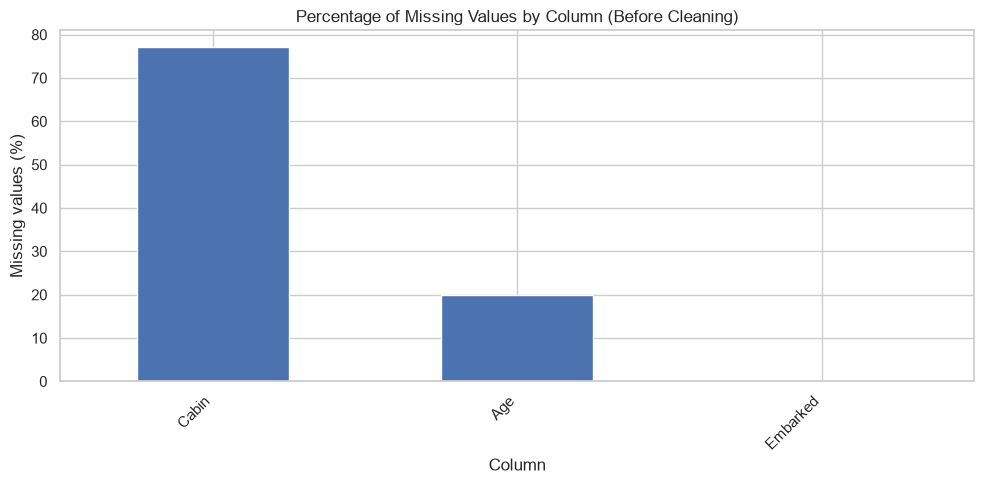

Observation: 'Cabin' has the highest missingness at 77.1%. Columns with substantial missingness need careful handling before analysis.


In [5]:
missing_pct = (df_original.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
missing_pct[missing_pct > 0].plot(kind="bar", ax=ax)
ax.set_title("Percentage of Missing Values by Column (Before Cleaning)")
ax.set_xlabel("Column")
ax.set_ylabel("Missing values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/01_missing_values.png", dpi=300, bbox_inches="tight")
plt.show()

if len(missing_pct[missing_pct > 0]):
    top_col = missing_pct[missing_pct > 0].index[0]
    top_pct = missing_pct[top_col]
    print(f"Observation: '{top_col}' has the highest missingness at {top_pct:.1f}%. "
          "Columns with substantial missingness need careful handling before analysis.")
else:
    print("Observation: no missing values were found.")

## 6. Duplicate-row check
The exact-duplicate count tells us whether fully identical records were present. Duplicate removal is deliberately limited to full-row matches; two passengers can share the same age, class, fare, or other attributes without being the same person.

In [6]:
duplicate_counts = pd.Series({
    "Rows before cleaning": len(df_original),
    "Exact duplicate rows found": int(df_original.duplicated().sum()),
    "Rows after exact duplicate removal": len(df_original.drop_duplicates())
})
display(duplicate_counts.to_frame("count"))

print("Observation:", 
      f"{int(df_original.duplicated().sum())} exact duplicate row(s) were found. "
      "Only exact full-row duplicates were removed; similar-looking records were retained.")

,count
Rows before cleaning,891
Exact duplicate rows found,0
Rows after exact duplicate removal,891


Observation: 0 exact duplicate row(s) were found. Only exact full-row duplicates were removed; similar-looking records were retained.


## 7. Feature distributions
Histograms show how numeric values are distributed. We plot Age, Fare, SibSp (siblings/spouses aboard), and Parch (parents/children aboard). Fare may be right-skewed because a smaller number of passengers paid much higher fares.

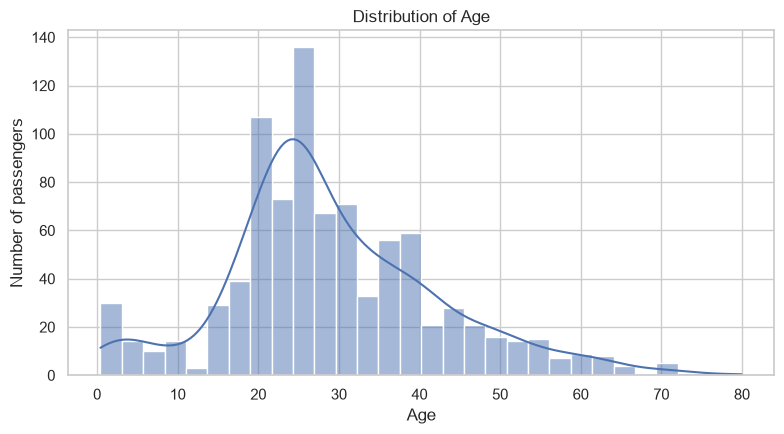

Observation for Age: median=26.00, mean=29.11, minimum=0.42, maximum=80.00.


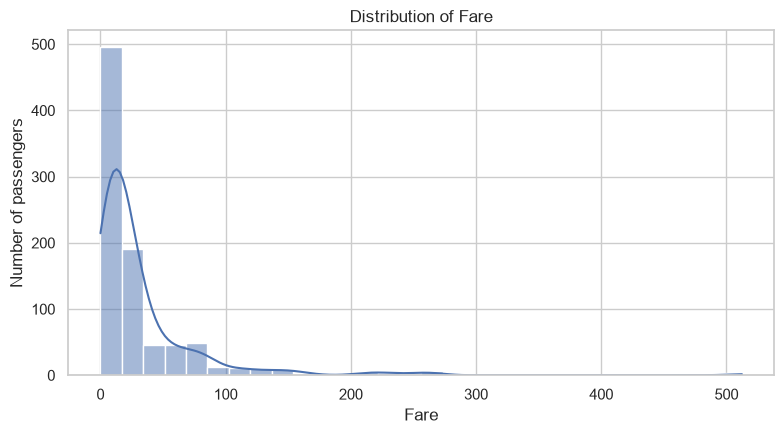

Observation for Fare: median=14.45, mean=32.20, minimum=0.00, maximum=512.33.
  The mean is noticeably above the median, suggesting possible right-skew.


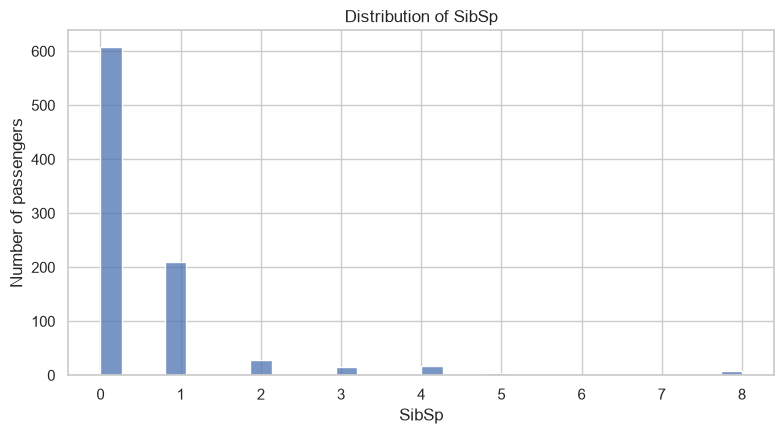

Observation for SibSp: median=0.00, mean=0.52, minimum=0.00, maximum=8.00.
  The mean is noticeably above the median, suggesting possible right-skew.


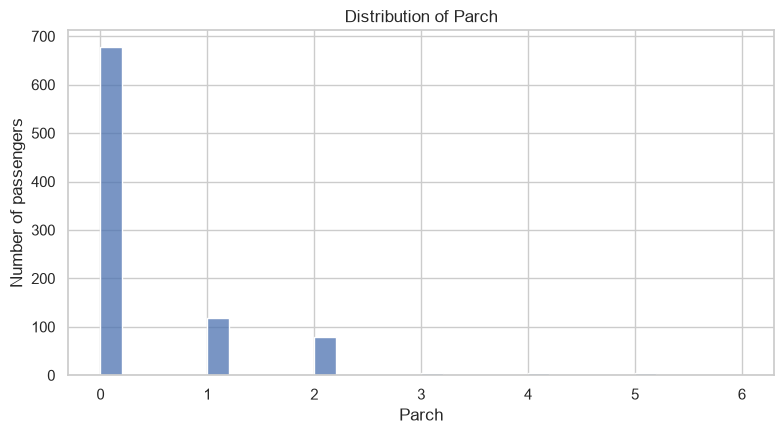

Observation for Parch: median=0.00, mean=0.38, minimum=0.00, maximum=6.00.
  The mean is noticeably above the median, suggesting possible right-skew.


In [7]:
numeric_for_hist = [c for c in ["Age", "Fare", "SibSp", "Parch"] if c in df_clean.columns]
for col in numeric_for_hist:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(data=df_clean, x=col, bins=30, kde=(df_clean[col].nunique() > 10), ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of passengers")
    plt.tight_layout()
    safe_name = col.lower()
    fig.savefig(f"{OUTPUT_DIR}/02_distribution_{safe_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

    s = df_clean[col].dropna()
    if len(s):
        print(f"Observation for {col}: median={s.median():.2f}, mean={s.mean():.2f}, "
              f"minimum={s.min():.2f}, maximum={s.max():.2f}.")
        if s.mean() > s.median() * 1.2:
            print("  The mean is noticeably above the median, suggesting possible right-skew.")

## 8. Categorical feature counts
Bar charts compare counts for the main categorical variables. Counts describe the composition of this dataset; they do not explain why the groups differ.

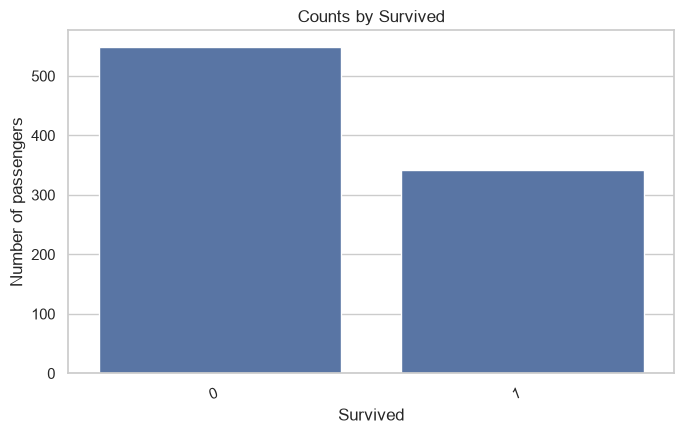

Observation for Survived: most common category is np.int64(0) with 549 records.


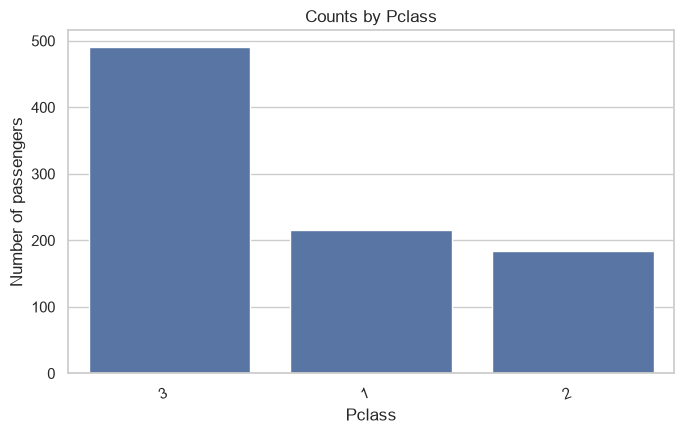

Observation for Pclass: most common category is np.int64(3) with 491 records.


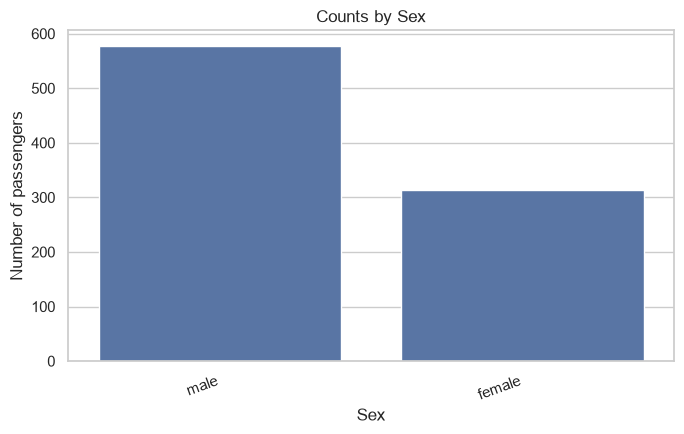

Observation for Sex: most common category is 'male' with 577 records.


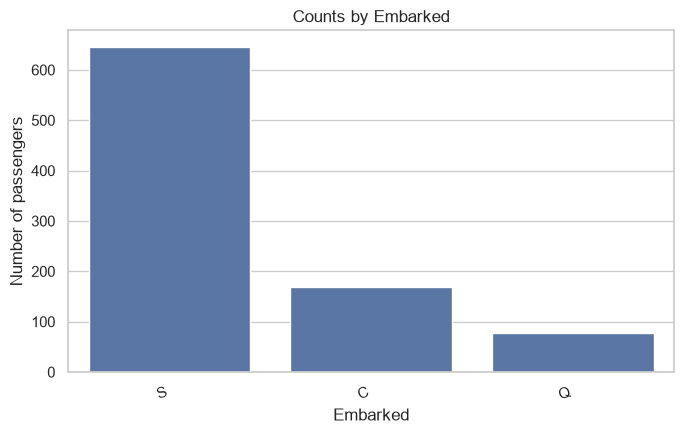

Observation for Embarked: most common category is 'S' with 646 records.


In [8]:
categorical_for_counts = [c for c in ["Survived", "Pclass", "Sex", "Embarked"] if c in df_clean.columns]
for col in categorical_for_counts:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    order = df_clean[col].value_counts(dropna=False).index
    sns.countplot(data=df_clean, x=col, order=order, ax=ax)
    ax.set_title(f"Counts by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of passengers")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/03_count_{col.lower()}.png", dpi=300, bbox_inches="tight")
    plt.show()

    counts = df_clean[col].value_counts(dropna=False)
    if not counts.empty:
        print(f"Observation for {col}: most common category is {counts.index[0]!r} "
              f"with {counts.iloc[0]} records.")

## 9. Boxplots and IQR outlier detection
A boxplot highlights the median, interquartile range, and points beyond the whiskers. We use the IQR rule to **flag** potential outliers; we do not automatically delete them. Extreme fares may be genuine observations and need context before removal.

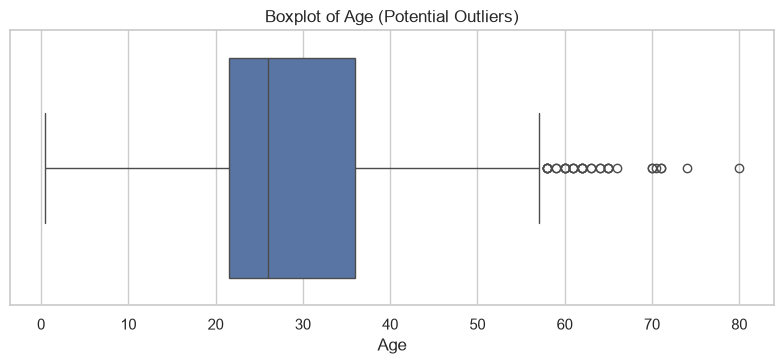

Observation for Age: the IQR rule flags 33 value(s) (3.7% of non-missing values) as potential outliers.


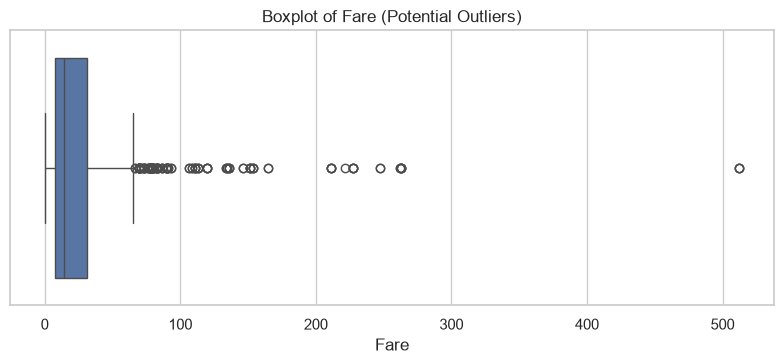

Observation for Fare: the IQR rule flags 116 value(s) (13.0% of non-missing values) as potential outliers.


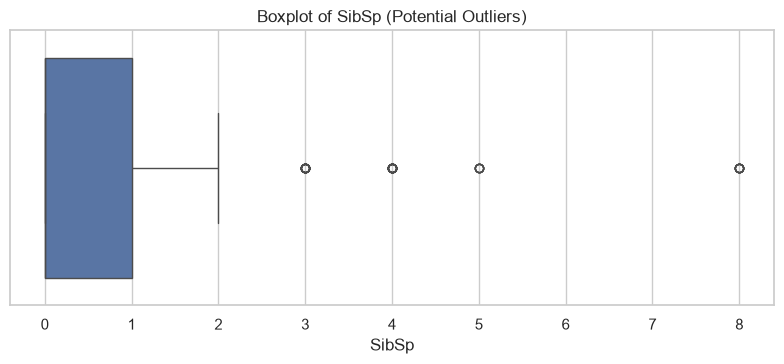

Observation for SibSp: the IQR rule flags 46 value(s) (5.2% of non-missing values) as potential outliers.


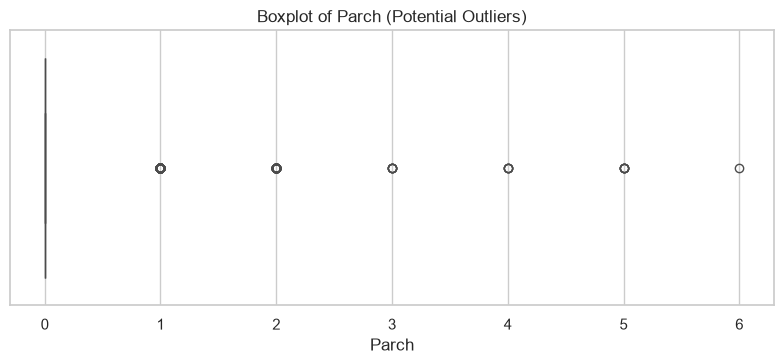

Observation for Parch: the IQR rule flags 213 value(s) (23.9% of non-missing values) as potential outliers.


,feature,Q1,Q3,IQR,lower_fence,upper_fence,potential_outlier_count,potential_outlier_percent
0,Age,21.50,36.0,14.50,-0.25,57.75,33,3.70
1,Fare,7.91,31.0,23.09,-26.72,65.63,116,13.02
2,SibSp,0.00,1.0,1.00,-1.50,2.50,46,5.16
3,Parch,0.00,0.0,0.00,0.00,0.00,213,23.91


In [9]:
numeric_for_box = [c for c in ["Age", "Fare", "SibSp", "Parch"] if c in df_clean.columns]
outlier_summary = []
for col in numeric_for_box:
    series = df_clean[col].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_summary.append({
        "feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": lower, "upper_fence": upper,
        "potential_outlier_count": count,
        "potential_outlier_percent": round(count / len(series) * 100, 2) if len(series) else 0
    })

    fig, ax = plt.subplots(figsize=(8, 3.8))
    sns.boxplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col} (Potential Outliers)")
    ax.set_xlabel(col)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/04_boxplot_{col.lower()}.png", dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Observation for {col}: the IQR rule flags {count} value(s) "
          f"({count / len(series) * 100:.1f}% of non-missing values) as potential outliers.")

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df.round(2))
outlier_df.to_csv(f"{OUTPUT_DIR}/outlier_summary.csv", index=False)

## 10. Correlation heatmap
Pearson correlation is calculated only for numeric columns. Correlation indicates linear association, not causation. The `Survived` column is coded as 0/1, so its correlation with numeric features is a descriptive association only.

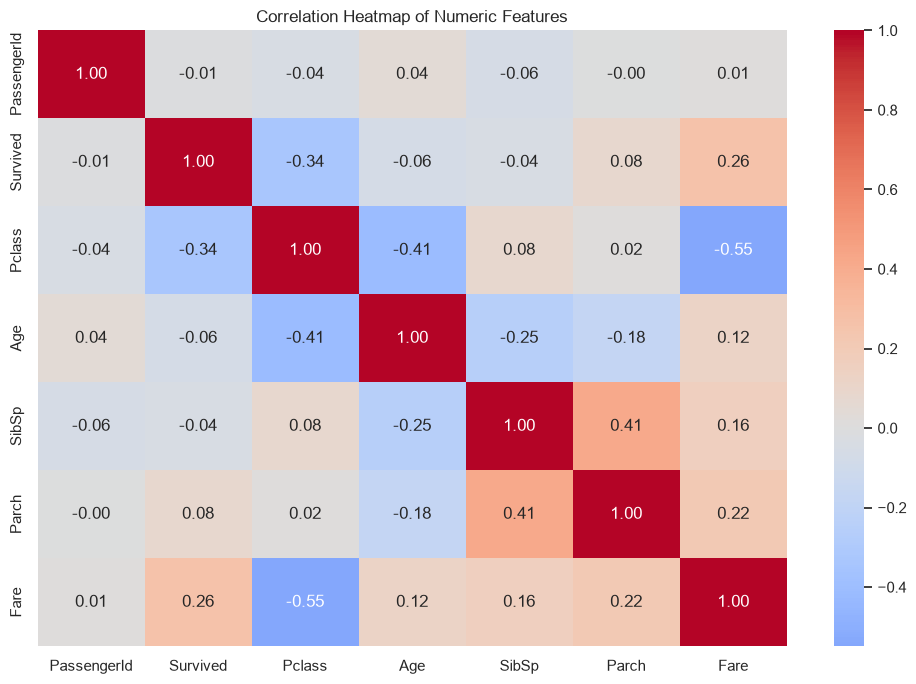

Observation: the strongest absolute numeric correlation in this matrix is Pclass vs Fare (r=-0.55). This is association, not proof that one variable causes the other.


In [10]:
numeric_df = df_clean.select_dtypes(include=np.number)
corr = numeric_df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/05_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Find strongest off-diagonal correlation for a concise evidence-based note.
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
if not corr_pairs.empty:
    strongest_pair = corr_pairs.abs().idxmax()
    strongest_value = corr.loc[strongest_pair[0], strongest_pair[1]]
    print(f"Observation: the strongest absolute numeric correlation in this matrix is "
          f"{strongest_pair[0]} vs {strongest_pair[1]} (r={strongest_value:.2f}). "
          "This is association, not proof that one variable causes the other.")
else:
    print("Observation: there were not enough numeric columns to compute pairwise correlations.")

## 11. Pairwise scatter plots
The scatterplot matrix explores pairwise relationships among a small set of numeric variables. We sample at most 400 rows to keep the figure readable and fast; the random seed makes the sample reproducible.

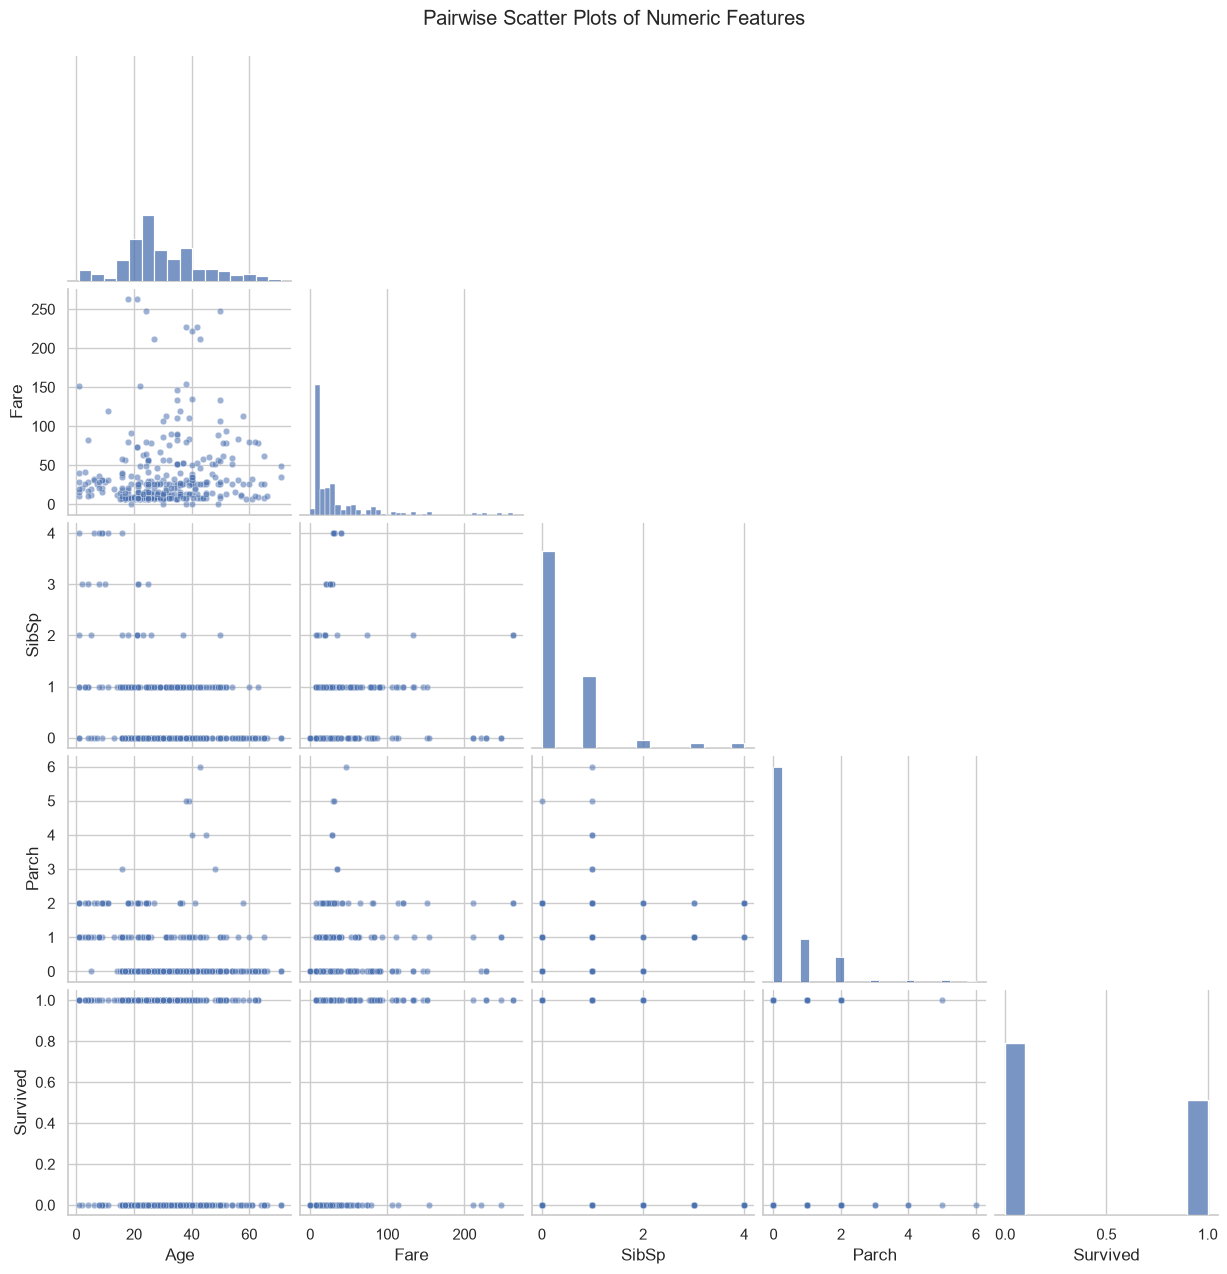

Observation: inspect the off-diagonal panels for visible trends, clusters, or unusual points. If the points are widely scattered, the pair may have a weak linear relationship.


In [11]:
pair_cols = [c for c in ["Age", "Fare", "SibSp", "Parch", "Survived"] if c in numeric_df.columns]
pair_data = numeric_df[pair_cols].dropna()
if len(pair_data) > 400:
    pair_data = pair_data.sample(n=400, random_state=42)

if len(pair_cols) >= 2 and not pair_data.empty:
    g = sns.pairplot(pair_data, diag_kind="hist", corner=True, plot_kws={"alpha": 0.55, "s": 22})
    g.fig.suptitle("Pairwise Scatter Plots of Numeric Features", y=1.02)
    g.fig.savefig(f"{OUTPUT_DIR}/06_pairwise_scatterplots.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Observation: inspect the off-diagonal panels for visible trends, clusters, or unusual points. "
          "If the points are widely scattered, the pair may have a weak linear relationship.")
else:
    print("Not enough numeric features available for pairwise scatter plots.")

## 12. Optional group comparison: survival rate by passenger class
This chart is included to demonstrate how EDA can lead to a practical, dataset-specific takeaway. It does not establish causation and should be interpreted in historical context.

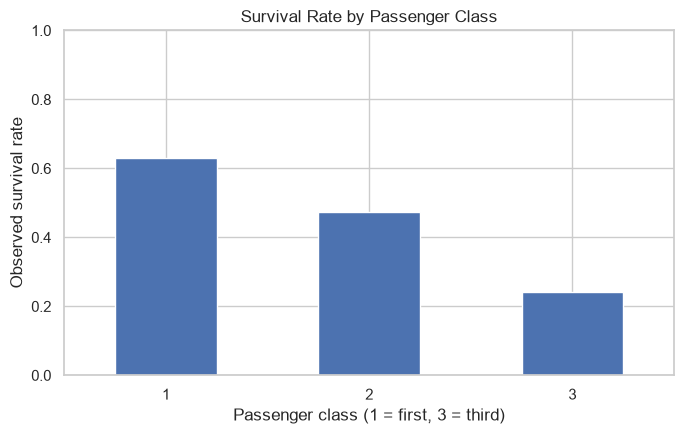

,survival_percent
Pclass,
1,63.0
2,47.3
3,24.2


Observation: survival rates differ across passenger classes in this dataset. This is a descriptive pattern; other factors may also be associated with survival.


In [12]:
if {"Pclass", "Survived"}.issubset(df_clean.columns):
    survival_by_class = df_clean.groupby("Pclass", observed=True)["Survived"].mean().sort_index()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    survival_by_class.plot(kind="bar", ax=ax)
    ax.set_title("Survival Rate by Passenger Class")
    ax.set_xlabel("Passenger class (1 = first, 3 = third)")
    ax.set_ylabel("Observed survival rate")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=0)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/07_survival_rate_by_class.png", dpi=300, bbox_inches="tight")
    plt.show()

    display((survival_by_class * 100).round(1).rename("survival_percent").to_frame())
    if len(survival_by_class) > 1:
        print("Observation: survival rates differ across passenger classes in this dataset. "
              "This is a descriptive pattern; other factors may also be associated with survival.")

## 13. Export cleaned data and final profile
Export the cleaned analysis dataset and a final missing-value profile so the work is reproducible. The original dataset remains unchanged in `df_original`.

In [13]:
df_clean.to_csv(f"{OUTPUT_DIR}/titanic_cleaned.csv", index=False)

final_profile = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "non_null": df_clean.notna().sum(),
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2),
    "unique_values": df_clean.nunique(dropna=True)
})
final_profile.to_csv(f"{OUTPUT_DIR}/final_data_profile.csv")
display(final_profile)

print("Saved cleaned dataset and profile in:", OUTPUT_DIR)

,dtype,non_null,missing_count,missing_percent,unique_values
PassengerId,int64,891,0,0.0,891
Survived,int64,891,0,0.0,2
Pclass,int64,891,0,0.0,3
Name,str,891,0,0.0,891
Sex,str,891,0,0.0,2
Age,float64,891,0,0.0,89
SibSp,int64,891,0,0.0,7
Parch,int64,891,0,0.0,7
Ticket,str,891,0,0.0,681
Fare,float64,891,0,0.0,248


Saved cleaned dataset and profile in: eda_outputs


## 14. Conclusions and limitations
Use the generated tables and charts to complete the summary below with your actual results. Do not copy a claim unless the notebook output supports it.

1. **Data quality:** Report the original row/column count, missing values, and exact duplicate count.
2. **Cleaning:** Explain the grouped-median age imputation, mode imputation for `Embarked`, exact-duplicate removal, and why `Cabin` was excluded from the cleaned analysis.
3. **Distributions:** Describe the shape and range of age and fare; mention skew only if supported by the histogram and mean/median.
4. **Outliers:** Report IQR-flagged counts and explain why flagged points were retained pending domain review.
5. **Relationships:** Name a correlation or scatterplot pattern visible in the figures; do not claim causation.
6. **Limitations:** This is a historical, single-ship dataset with missing fields and limited generalizability. Imputation may change distributions. Correlation and group comparisons are descriptive, not causal.

## 15. Download the outputs
Run this final cell to bundle all exported figures, tables, and the cleaned dataset into a ZIP file for your GitHub repository or report.

In [14]:
import shutil
zip_path = shutil.make_archive("codenova_task1_eda_outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)

Created: c:\Users\chand\OneDrive\Desktop\CodeNova_Task1_EDA\codenova_task1_eda_outputs.zip
